<a href="https://colab.research.google.com/github/PavloMytsko/lab3-ocr-variant10/blob/main/notebooks/Lab3-MytskoPavlo-Variant10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Лабораторна робота №3
## Побудова рішення розпізнавання тексту із застосуванням ШІ

**Дисципліна:** Технології ШІ в інженерії даних
**Виконав:** Мицко Павло, група ПЗ-46
**Варіант:** 10
**Завдання:** порівняння Tesseract та EasyOCR для розпізнавання тексту на чеках

## 1. Personal Information and Reproducibility



In [4]:
# Завдання 1. Персональні параметри та відтворюваність

STUDENT = "Мицко Павло"
GROUP = "ПЗ-46"
VARIANT = 10
STUDENT_ID = 534

SEED = 1000 * VARIANT + STUDENT_ID

print("Студент:", STUDENT)
print("Група:", GROUP)
print("Варіант:", VARIANT)
print("STUDENT_ID:", STUDENT_ID)
print("SEED:", SEED)

assert SEED == 10534

print("Персональні параметри задано правильно.")

Студент: Мицко Павло
Група: ПЗ-46
Варіант: 10
STUDENT_ID: 534
SEED: 10534
Персональні параметри задано правильно.


## 2. Installing and Importing Libraries

In [1]:
# Завдання 2. Встановлення системного OCR та Python-бібліотек

!sudo apt-get update -qq
!sudo apt-get install -y -qq tesseract-ocr tesseract-ocr-ukr tesseract-ocr-eng

%pip install -q pytesseract rapidfuzz easyocr datasets jiwer

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package tesseract-ocr-ukr.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ukr_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ukr (1:4.1.0-2) ...
Setting up tesseract-ocr-ukr (1:4.1.0-2) ...


In [2]:
# Перевірка встановлення Tesseract та мовних моделей

!tesseract --version
!tesseract --list-langs

tesseract 5.3.4
 leptonica-1.82.0
  libgif 5.2.1 : libjpeg 8d (libjpeg-turbo 2.1.5) : libpng 1.6.43 : libtiff 4.5.1 : zlib 1.3 : libwebp 1.3.2 : libopenjp2 2.5.0
 Found AVX2
 Found AVX
 Found FMA
 Found SSE4.1
 Found OpenMP 201511
 Found libarchive 3.7.2 zlib/1.3 liblzma/5.4.5 bz2lib/1.0.8 liblz4/1.9.4 libzstd/1.5.5
 Found libcurl/8.5.0 OpenSSL/3.0.13 zlib/1.3 brotli/1.1.0 zstd/1.5.5 libidn2/2.3.7 libpsl/0.21.2 (+libidn2/2.3.7) libssh/0.10.6/openssl/zlib nghttp2/1.59.0 librtmp/2.3 OpenLDAP/2.6.10
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
osd
ukr


In [5]:
# Імпорт бібліотек

import os
import re
import json
import glob
import time
import random
import hashlib
import platform
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageDraw, ImageFont, ExifTags
from scipy import stats
from rapidfuzz.distance import Levenshtein
from datasets import load_dataset

import pytesseract
import easyocr
import torch

random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

print("Python:", platform.python_version())
print("OpenCV:", cv2.__version__)
print("Tesseract:", pytesseract.get_tesseract_version())
print("EasyOCR:", easyocr.__version__)
print("GPU доступний:", torch.cuda.is_available())
print("Бібліотеки імпортовано успішно.")

Python: 3.13.18
OpenCV: 5.0.0
Tesseract: 5.3.4
EasyOCR: 1.7.2
GPU доступний: False
Бібліотеки імпортовано успішно.


## 3. Hypotheses Before Experiments


### Гіпотези до проведення експериментів

Гіпотези сформульовано до запуску OCR-експериментів. Після отримання результатів кожна гіпотеза буде оцінена як підтверджена або спростована.

#### Гіпотеза 1. Якість на зображеннях без повороту

На синтетичних зображеннях без повороту Tesseract матиме CER не більше 5%, а EasyOCR — не більше 8%. Очікується, що на чистому друкованому тексті Tesseract буде точнішим, оскільки зображення мають просте розташування тексту та високу контрастність.

#### Гіпотеза 2. Стійкість до повороту

При повороті на 10° CER Tesseract перевищить 15%, тоді як CER EasyOCR не перевищить 12%. Очікується, що EasyOCR буде стійкішим до значних поворотів завдяки нейромережевій детекції текстових областей. Передбачається, що криві якості інструментів перетнуться в діапазоні від 4° до 8°.

#### Гіпотеза 3. Вплив вирівнювання нахилу

Застосування deskew для зображень, повернутих на 10° і 15°, зменшить середній CER Tesseract щонайменше на 30%, а EasyOCR — щонайменше на 15%. На власних фотографіях чеків під кутом deskew має зменшити середній CER щонайменше на 25% порівняно з необробленими фотографіями.

## 4. Text Normalization and Metrics

### Правила нормалізації тексту

Перед обчисленням метрик еталонний і розпізнаний тексти нормалізуються однаково:

- використовується Unicode-нормалізація NFC;
- різні види апострофа замінюються на звичайний апостроф;
- декілька пробілів і переносів рядків замінюються одним пробілом;
- пробіли на початку та в кінці вилучаються;
- регістр і пунктуація зберігаються, оскільки вони є частиною точного результату OCR.

CER і WER повертаються як частки: наприклад, 0.05 відповідає 5%.

In [6]:
# Завдання 4. Нормалізація тексту

import unicodedata

APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"

def normalize_text(text):
    """Нормалізує текст перед обчисленням CER і WER."""
    text = unicodedata.normalize("NFC", str(text))

    for apostrophe in APOSTROPHES:
        text = text.replace(apostrophe, "'")

    text = re.sub(r"\s+", " ", text).strip()
    return text


example_text = "  Захар\u2019   Беркут\nІван Франко  "
normalized_example = normalize_text(example_text)

print("До нормалізації:")
print(repr(example_text))

print("\nПісля нормалізації:")
print(repr(normalized_example))

assert normalized_example == "Захар' Беркут Іван Франко"

print("\nНормалізація працює правильно.")

До нормалізації:
'  Захар’   Беркут\nІван Франко  '

Після нормалізації:
"Захар' Беркут Іван Франко"

Нормалізація працює правильно.


In [7]:
# Реалізація метрик CER і WER

def cer(ground_truth, prediction):
    """
    Character Error Rate:
    кількість вставок, видалень і замін символів,
    поділена на кількість символів еталону.
    """
    ground_truth = normalize_text(ground_truth)
    prediction = normalize_text(prediction)

    errors = Levenshtein.distance(ground_truth, prediction)
    return errors / max(1, len(ground_truth))


def wer(ground_truth, prediction):
    """
    Word Error Rate:
    кількість вставок, видалень і замін слів,
    поділена на кількість слів еталону.
    """
    ground_truth_words = normalize_text(ground_truth).split()
    prediction_words = normalize_text(prediction).split()

    errors = Levenshtein.distance(
        ground_truth_words,
        prediction_words
    )

    return errors / max(1, len(ground_truth_words))


# Перевірка метрик на простих прикладах
cer_example = cer("кіт", "кит")
wer_example = wer("один два три", "один два")

print(f"CER для 'кіт' → 'кит': {cer_example:.3f} ({cer_example:.1%})")
print(
    "WER для 'один два три' → 'один два': "
    f"{wer_example:.3f} ({wer_example:.1%})"
)

assert np.isclose(cer_example, 1 / 3)
assert np.isclose(wer_example, 1 / 3)
assert cer("текст", "текст") == 0
assert wer("точний текст", "точний текст") == 0

print("\nУсі перевірки CER і WER пройдено.")

CER для 'кіт' → 'кит': 0.333 (33.3%)
WER для 'один два три' → 'один два': 0.333 (33.3%)

Усі перевірки CER і WER пройдено.


In [8]:
# Генератор випадкових чисел для бутстрепу й експериментів

rng = np.random.default_rng(SEED)

print("Генератор створено з SEED =", SEED)

Генератор створено з SEED = 10534


## 5. Synthetic Dataset Creation

In [14]:
# Завантаження дев'яти розділів через звичайні HTML-сторінки

%pip install -q beautifulsoup4

import time
import requests

from bs4 import BeautifulSoup
from urllib.parse import quote

BASE_TITLE = "Твори (Франко, 1956–1962)/13/Захар Беркут"
CHAPTERS = ["I", "II", "III", "IV", "V", "VI", "VII", "VIII", "IX"]


def load_chapter_html(chapter):
    title = f"{BASE_TITLE}/{chapter}"
    encoded_title = quote(
        title.replace(" ", "_"),
        safe="/()_,–"
    )

    url = f"https://uk.wikisource.org/wiki/{encoded_title}"

    response = None

    for attempt in range(5):
        response = requests.get(
            url,
            timeout=90,
            headers={
                "User-Agent": "Lab3-OCR-Student-Project/1.0",
                "Accept-Language": "uk,en;q=0.8"
            }
        )

        if response.status_code == 200:
            break

        if response.status_code == 429:
            wait_seconds = 20 + attempt * 10
            print(
                f"Розділ {chapter}: обмеження запитів, "
                f"очікування {wait_seconds} с..."
            )
            time.sleep(wait_seconds)
            continue

        response.raise_for_status()

    if response is None or response.status_code != 200:
        raise RuntimeError(
            f"Не вдалося завантажити розділ {chapter}"
        )

    soup = BeautifulSoup(response.text, "html.parser")

    content = soup.select_one(".prp-pages-output")

    if content is None:
        content = soup.select_one(
            "#mw-content-text .mw-parser-output"
        )

    if content is None:
        raise RuntimeError(
            f"Не знайдено текст розділу {chapter}"
        )

    # Вилучаємо службові елементи сторінки
    for element in content.select(
        "script, style, table, sup, "
        ".mw-editsection, .ws-noexport, "
        ".noprint, .mw-empty-elt"
    ):
        element.decompose()

    chapter_text = content.get_text(
        separator=" ",
        strip=True
    )

    chapter_text = re.sub(
        r"\s+",
        " ",
        chapter_text
    ).strip()

    if len(chapter_text) < 1000:
        raise RuntimeError(
            f"Розділ {chapter} має лише "
            f"{len(chapter_text)} символів"
        )

    return chapter_text


chapter_texts = []

for position, chapter in enumerate(CHAPTERS):
    chapter_text = load_chapter_html(chapter)
    chapter_texts.append(chapter_text)

    print(
        f"Розділ {chapter}: "
        f"{len(chapter_text)} символів"
    )

    # Пауза, щоб не перевищувати обмеження сайту
    if position < len(CHAPTERS) - 1:
        time.sleep(5)

full_text = "\n".join(chapter_texts)

print("\nЗагальна кількість символів:", len(full_text))
print("Усі дев'ять розділів завантажено успішно.")

Розділ I: 36259 символів
Розділ II: 26240 символів
Розділ III: 56182 символів
Розділ IV: 39474 символів
Розділ V: 35346 символів
Розділ VI: 42974 символів
Розділ VII: 27487 символів
Розділ VIII: 30719 символів
Розділ IX: 17081 символів

Загальна кількість символів: 311770
Усі дев'ять розділів завантажено успішно.


In [16]:
# Формування персонального набору з 40 рядків

clean_text = full_text.replace("\u00a0", " ")
clean_text = re.sub(r"\[\d+\]", "", clean_text)
clean_text = re.sub(r"\s+", " ", clean_text).strip()

# Поділ тексту на окремі речення
sentences = re.split(
    r"(?<=[.!?…])\s+",
    clean_text
)

sentences = [
    normalize_text(sentence)
    for sentence in sentences
]

# Службові фрагменти, які не повинні потрапити в еталон
excluded_fragments = [
    "Вікіджерела",
    "Отримано з",
    "Твори в 20 томах",
    "Creative Commons",
    "Політика конфіденційності",
    "Переглянути історію"
]


def is_valid_sentence(sentence):
    """Перевіряє придатність речення для синтетичного OCR."""
    has_ukrainian_letters = bool(
        re.search(
            r"[А-Яа-яІіЇїЄєҐґ]",
            sentence
        )
    )

    has_excluded_fragment = any(
        fragment in sentence
        for fragment in excluded_fragments
    )

    return (
        55 <= len(sentence) <= 150
        and len(sentence.split()) >= 7
        and has_ukrainian_letters
        and not has_excluded_fragment
    )


candidate_sentences = [
    sentence
    for sentence in sentences
    if is_valid_sentence(sentence)
]

if len(candidate_sentences) < 40:
    raise RuntimeError(
        "Недостатньо речень: "
        f"знайдено {len(candidate_sentences)}"
    )

# Окремий генератор із персональним SEED
text_rng = np.random.default_rng(SEED)

selected_indices = text_rng.choice(
    len(candidate_sentences),
    size=40,
    replace=False
)

# Сортуємо індекси, щоб речення зберігали порядок твору
selected_indices = sorted(
    int(index)
    for index in selected_indices
)

synthetic_lines = [
    candidate_sentences[index]
    for index in selected_indices
]

assert len(synthetic_lines) == 40
assert len(set(synthetic_lines)) == 40
assert all(
    55 <= len(line) <= 150
    for line in synthetic_lines
)

print("Кандидатів знайдено:", len(candidate_sentences))
print("Вибрано рядків:", len(synthetic_lines))

print("\nПерші п'ять вибраних рядків:")

for number, line in enumerate(
    synthetic_lines[:5],
    start=1
):
    print(f"{number}. {line}")

Кандидатів знайдено: 1584
Вибрано рядків: 40

Перші п'ять вибраних рядків:
1. Це новий тухольський боярин, Тугар Вовк, справляв великі лови на грубу звірину.
2. Ще сонечко не зараз мало сходити, а вже ловецьке товариство вирушило з табору.
3. Побачивши страшного ворога тут-же перед собою, вони зблідли й затремтіли.
4. Дрож пройшла у всіх по тілі на той вид; бояри стали, мов укопані.
5. Тухольські пасемці на сплетені з галуззя мари положили трупа, а за ним потягли й ведмедя.


In [17]:
# Збереження персонального еталонного набору та метаданих

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

reference_path = DATA_DIR / "synthetic_reference.txt"
metadata_path = DATA_DIR / "synthetic_metadata.json"

reference_text = "\n".join(synthetic_lines) + "\n"
reference_path.write_text(reference_text, encoding="utf-8")

reference_sha256 = hashlib.sha256(
    reference_path.read_bytes()
).hexdigest()

metadata = {
    "student": "Мицка Павло",
    "group": "ПЗ-46",
    "variant": VARIANT,
    "student_id": STUDENT_ID,
    "seed": SEED,
    "source": "Іван Франко — Захар Беркут",
    "source_url": (
        "https://uk.wikisource.org/wiki/"
        "Твори_(Франко,_1956–1962)/13/Захар_Беркут"
    ),
    "number_of_lines": len(synthetic_lines),
    "sha256": reference_sha256
}

metadata_path.write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("Еталонний файл:", reference_path)
print("Файл метаданих:", metadata_path)
print("Кількість рядків:", len(synthetic_lines))
print("SEED:", SEED)
print("SHA-256:", reference_sha256)

Еталонний файл: data/synthetic_reference.txt
Файл метаданих: data/synthetic_metadata.json
Кількість рядків: 40
SEED: 10534
SHA-256: cc80df86f007e10ec6c7530b8c1aa0a470a77f3f4ececcfd751e2db5e5a856ed


In [18]:
!git add data/synthetic_reference.txt data/synthetic_metadata.json
!git commit -m "Create personalized synthetic reference dataset"
!git status

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [20]:
# Створення синтетичних зображень із персональних рядків

SYNTHETIC_DIR = Path("data/synthetic/clean")
SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)
from matplotlib import font_manager

FONT_PATH = font_manager.findfont("DejaVu Sans")
print("Знайдений шрифт:", FONT_PATH)
FONT_SIZE = 38
IMAGE_WIDTH = 1600
MARGIN = 50
LINE_SPACING = 16

font = ImageFont.truetype(FONT_PATH, FONT_SIZE)


def wrap_text_by_width(text, font, max_width):
    """Розбиває текст на рядки відповідно до ширини зображення."""
    words = text.split()
    wrapped_lines = []
    current_line = ""

    temporary_image = Image.new("L", (10, 10), color=255)
    temporary_draw = ImageDraw.Draw(temporary_image)

    for word in words:
        candidate = (
            f"{current_line} {word}".strip()
        )

        left, top, right, bottom = temporary_draw.textbbox(
            (0, 0),
            candidate,
            font=font
        )

        if right - left <= max_width:
            current_line = candidate
        else:
            if current_line:
                wrapped_lines.append(current_line)
            current_line = word

    if current_line:
        wrapped_lines.append(current_line)

    return wrapped_lines


synthetic_records = []

for sample_id, ground_truth in enumerate(
    synthetic_lines,
    start=1
):
    wrapped_lines = wrap_text_by_width(
        ground_truth,
        font,
        IMAGE_WIDTH - 2 * MARGIN
    )

    line_height = FONT_SIZE + LINE_SPACING
    image_height = (
        2 * MARGIN + len(wrapped_lines) * line_height
    )

    image = Image.new(
        "L",
        (IMAGE_WIDTH, image_height),
        color=255
    )
    draw = ImageDraw.Draw(image)

    y_position = MARGIN

    for text_line in wrapped_lines:
        draw.text(
            (MARGIN, y_position),
            text_line,
            fill=0,
            font=font
        )
        y_position += line_height

    file_name = f"synthetic_{sample_id:03d}.png"
    image_path = SYNTHETIC_DIR / file_name
    image.save(image_path)

    synthetic_records.append({
        "sample_id": sample_id,
        "image_path": str(image_path),
        "ground_truth": ground_truth,
        "width": image.width,
        "height": image.height
    })

synthetic_df = pd.DataFrame(synthetic_records)

synthetic_csv_path = Path(
    "data/synthetic/synthetic_dataset.csv"
)
synthetic_df.to_csv(
    synthetic_csv_path,
    index=False,
    encoding="utf-8"
)

print("Створено зображень:", len(synthetic_df))
print("Папка:", SYNTHETIC_DIR)
print("Таблиця метаданих:", synthetic_csv_path)
print("Розмір першого зображення:",
      Image.open(synthetic_df.iloc[0]["image_path"]).size)

display(synthetic_df.head())

Знайдений шрифт: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Створено зображень: 40
Папка: data/synthetic/clean
Таблиця метаданих: data/synthetic/synthetic_dataset.csv
Розмір першого зображення: (1600, 208)


,sample_id,image_path,ground_truth,width,height
0,1,data/synthetic/clean/synthetic_001.png,"Це новий тухольський боярин, Тугар Вовк, справляв великі лови на грубу звірину.",1600,208
1,2,data/synthetic/clean/synthetic_002.png,"Ще сонечко не зараз мало сходити, а вже ловецьке товариство вирушило з табору.",1600,208
2,3,data/synthetic/clean/synthetic_003.png,"Побачивши страшного ворога тут-же перед собою, вони зблідли й затремтіли.",1600,208
3,4,data/synthetic/clean/synthetic_004.png,"Дрож пройшла у всіх по тілі на той вид; бояри стали, мов укопані.",1600,154
4,5,data/synthetic/clean/synthetic_005.png,"Тухольські пасемці на сплетені з галуззя мари положили трупа, а за ним потягли й ведмедя.",1600,208


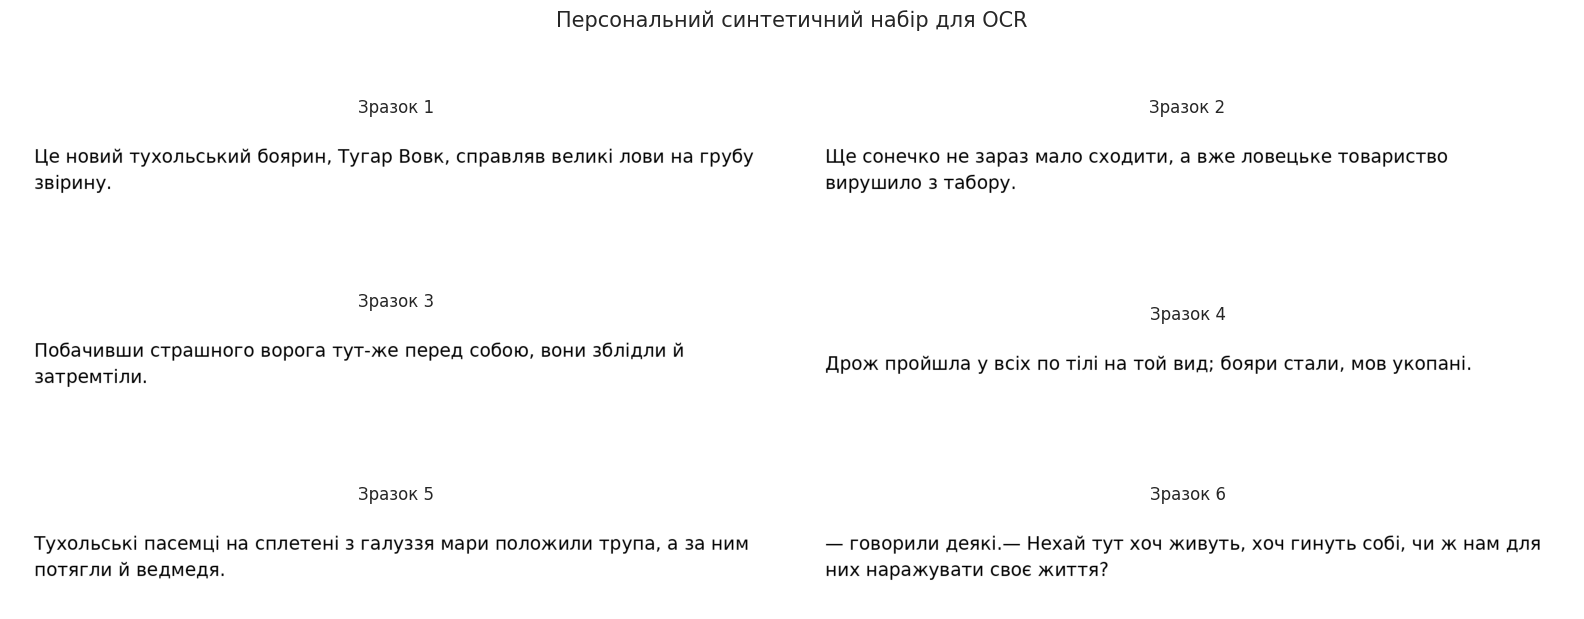

In [21]:
# Перегляд перших шести синтетичних зображень

fig, axes = plt.subplots(3, 2, figsize=(16, 7))

for axis, row in zip(
    axes.ravel(),
    synthetic_df.head(6).itertuples()
):
    image = Image.open(row.image_path)

    axis.imshow(image, cmap="gray")
    axis.set_title(f"Зразок {row.sample_id}")
    axis.axis("off")

plt.suptitle(
    "Персональний синтетичний набір для OCR",
    fontsize=15
)
plt.tight_layout()
plt.show()

## 6. Open Dataset CORD v2

In [22]:
# Завантаження тестової частини відкритого набору CORD v2

CORD_DATASET_NAME = "naver-clova-ix/cord-v2"

cord_test = load_dataset(
    CORD_DATASET_NAME,
    split="test"
)

print("Набір:", CORD_DATASET_NAME)
print("Кількість чеків у test:", len(cord_test))
print("Ознаки:", cord_test.features)

first_cord_sample = cord_test[0]

print("\nТип зображення:",
      type(first_cord_sample["image"]))
print("Розмір першого зображення:",
      first_cord_sample["image"].size)
print("Тип еталонної розмітки:",
      type(first_cord_sample["ground_truth"]))
print(
    "Початок еталонної розмітки:\n",
    first_cord_sample["ground_truth"][:500]
)

README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00004-b4aaeceff1d90e(…): reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00004-b4aaeceff1d90e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-7dbbe248962764(…): reconstructing file:   0%|          |  0.00B /  441MB            

data/train-00001-of-00004-7dbbe248962764(…): downloading bytes:           |  0.00B            

... (8 outputs left out)

Generating train split:   0%|          | 0/800 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

Набір: naver-clova-ix/cord-v2
Кількість чеків у test: 100
Ознаки: {'image': Image(mode=None, decode=True), 'ground_truth': Value('string')}

Тип зображення: <class 'PIL.PngImagePlugin.PngImageFile'>
Розмір першого зображення: (432, 648)
Тип еталонної розмітки: <class 'str'>
Початок еталонної розмітки:
 {"gt_parse": {"menu": {"nm": "-TICKET CP", "num": "901016", "cnt": "2", "price": "60.000", "itemsubtotal": "60.000"}, "sub_total": {"subtotal_price": "60.000", "discount_price": "-60.000", "tax_price": "5.455"}, "total": {"total_price": "60.000", "creditcardprice": "60.000", "menuqty_cnt": "2.00"}}, "meta": {"version": "2.0.0", "split": "test", "image_id": 0, "image_size": {"width": 432, "height": 648}}, "valid_line": [{"words": [{"quad": {"x2": 92, "y3": 412, "x3": 92, "y4": 412, "x1": 42, "y1"


In [23]:
# Перевірка структури еталонної розмітки CORD v2

cord_annotation = json.loads(
    first_cord_sample["ground_truth"]
)

print("Ключі верхнього рівня:",
      list(cord_annotation.keys()))
print("Довжина JSON-рядка:",
      len(first_cord_sample["ground_truth"]))

for key, value in cord_annotation.items():
    print(
        f"{key}: тип={type(value).__name__}"
    )

print("\nПочаток форматованої розмітки:")
print(
    json.dumps(
        cord_annotation,
        ensure_ascii=False,
        indent=2
    )[:3000]
)

Ключі верхнього рівня: ['gt_parse', 'meta', 'valid_line', 'roi', 'repeating_symbol', 'dontcare']
Довжина JSON-рядка: 5411
gt_parse: тип=dict
meta: тип=dict
valid_line: тип=list
roi: тип=dict
repeating_symbol: тип=list
dontcare: тип=list

Початок форматованої розмітки:
{
  "gt_parse": {
    "menu": {
      "nm": "-TICKET CP",
      "num": "901016",
      "cnt": "2",
      "price": "60.000",
      "itemsubtotal": "60.000"
    },
    "sub_total": {
      "subtotal_price": "60.000",
      "discount_price": "-60.000",
      "tax_price": "5.455"
    },
    "total": {
      "total_price": "60.000",
      "creditcardprice": "60.000",
      "menuqty_cnt": "2.00"
    }
  },
  "meta": {
    "version": "2.0.0",
    "split": "test",
    "image_id": 0,
    "image_size": {
      "width": 432,
      "height": 648
    }
  },
  "valid_line": [
    {
      "words": [
        {
          "quad": {
            "x2": 92,
            "y3": 412,
            "x3": 92,
            "y4": 412,
            "x1": 4

In [24]:
# Формування персональної вибірки CORD v2

CORD_SAMPLE_COUNT = 20
CORD_DIR = Path("data/cord_selected")
CORD_IMAGES_DIR = CORD_DIR / "images"

CORD_IMAGES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def extract_cord_reference(ground_truth_json):
    """Перетворює valid_line із CORD v2 на еталонний текст."""
    annotation = json.loads(ground_truth_json)
    extracted_lines = []

    for line in annotation.get("valid_line", []):
        words = line.get("words", [])
        word_texts = []

        for word in words:
            text = str(
                word.get("text", "")
            ).strip()

            if text:
                word_texts.append(text)

        if word_texts:
            extracted_lines.append(
                " ".join(word_texts)
            )

    return normalize_text(
        " ".join(extracted_lines)
    )


cord_rng = np.random.default_rng(SEED)

cord_selected_indices = sorted(
    cord_rng.choice(
        len(cord_test),
        size=CORD_SAMPLE_COUNT,
        replace=False
    ).tolist()
)

cord_records = []

for sample_number, dataset_index in enumerate(
    cord_selected_indices,
    start=1
):
    sample = cord_test[dataset_index]
    image = sample["image"].convert("RGB")
    reference_text = extract_cord_reference(
        sample["ground_truth"]
    )

    image_name = f"cord_{sample_number:03d}.png"
    image_path = CORD_IMAGES_DIR / image_name
    image.save(image_path)

    cord_records.append({
        "sample_id": sample_number,
        "dataset_index": dataset_index,
        "image_path": str(image_path),
        "ground_truth": reference_text,
        "width": image.width,
        "height": image.height
    })

cord_df = pd.DataFrame(cord_records)

cord_csv_path = CORD_DIR / "cord_selected.csv"
cord_df.to_csv(
    cord_csv_path,
    index=False,
    encoding="utf-8"
)

assert len(cord_df) == CORD_SAMPLE_COUNT
assert cord_df["dataset_index"].nunique() == CORD_SAMPLE_COUNT
assert cord_df["ground_truth"].str.len().min() > 0

print("SEED:", SEED)
print("Вибрані індекси:", cord_selected_indices)
print("Кількість вибраних чеків:", len(cord_df))
print("CSV-файл:", cord_csv_path)
print(
    "Діапазон довжини еталонних текстів:",
    cord_df["ground_truth"].str.len().min(),
    "—",
    cord_df["ground_truth"].str.len().max()
)

display(
    cord_df[
        [
            "sample_id",
            "dataset_index",
            "width",
            "height",
            "ground_truth"
        ]
    ].head()
)

SEED: 10534
Вибрані індекси: [5, 8, 19, 27, 28, 29, 35, 38, 40, 47, 53, 56, 62, 68, 70, 74, 81, 89, 93, 98]
Кількість вибраних чеків: 20
CSV-файл: data/cord_selected/cord_selected.csv
Діапазон довжини еталонних текстів: 53 — 394


,sample_id,dataset_index,width,height,ground_truth
0,1,5,2304,4096,TRAD KY TOAST CARTE 28.182 ITEMS 1.00 SUBTTL 28.182 PB-1 10% 2.818 TOTAL 31.000 CASH 31.000
1,2,8,864,1296,"1 [REG] BLACK SAKURA 45,455 1 COOKIE DOH SAUCES 0 1 NATA DE COCO 0 Sub Total 45,455 PB1 (10%) 4,545 Rounding 0 Total 50,000 Card Payment 50,000"
2,3,19,576,864,4 AMBUSH DBL CHS 60000 10 AMBUSH CHS BUR 100000 NET SALES 160000 TAX 16000 AMOUNT DUE 176000
3,4,27,864,1296,"PKT AYAM 33,000 GULAI OTAK 23,000 2.00 ITEMS SUBTOTAL 56,000 TAX 10% 5,600 TOTAL 61,600 CHARGE5 61,600"
4,5,28,1152,1728,"SAMGYOPSAL 2 194,000 SUL LUNG TANG 1 75,000 MAKOLI 1 100,000 Sub Total 369,000 Service 18,450 VAT 38,745 Discount 0 TOTAL 426,195"


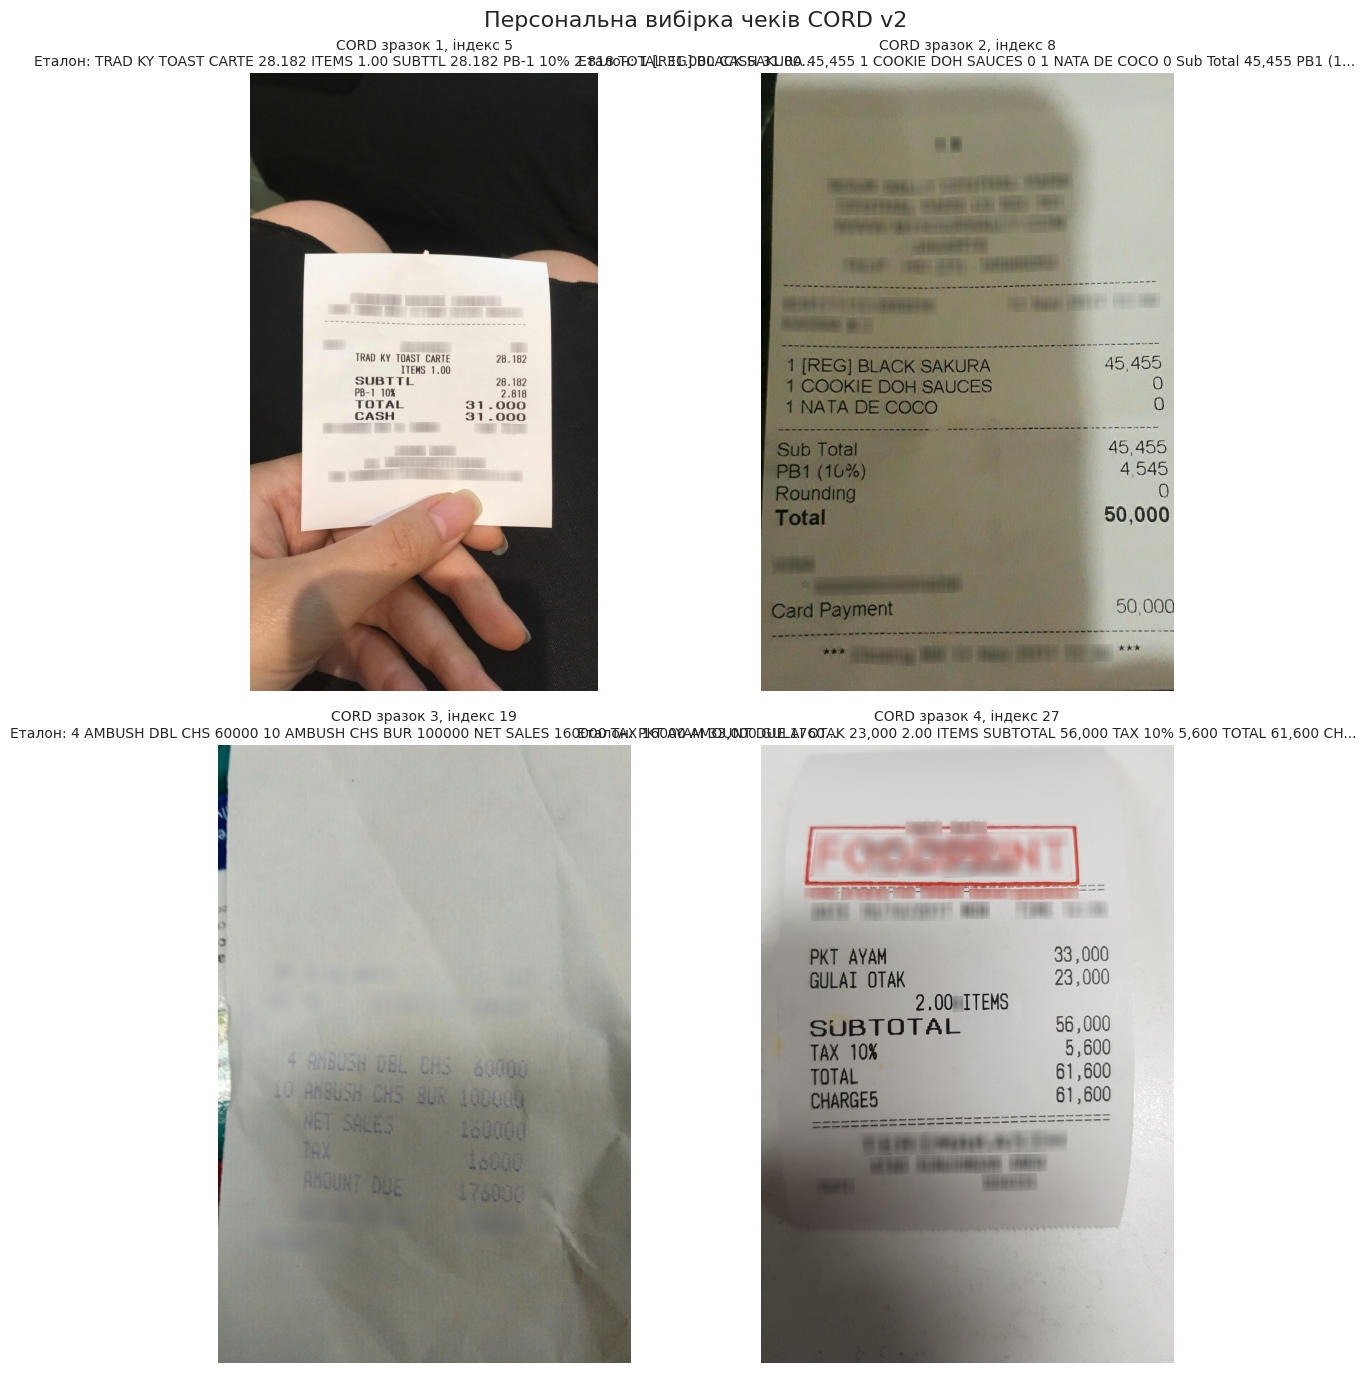

In [25]:
# Візуальна перевірка персональної вибірки CORD v2

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 14)
)

for axis, row in zip(
    axes.ravel(),
    cord_df.head(4).itertuples()
):
    image = Image.open(row.image_path)

    axis.imshow(image)
    axis.set_title(
        f"CORD зразок {row.sample_id}, "
        f"індекс {row.dataset_index}\n"
        f"Еталон: {row.ground_truth[:90]}...",
        fontsize=10
    )
    axis.axis("off")

plt.suptitle(
    "Персональна вибірка чеків CORD v2",
    fontsize=16
)
plt.tight_layout()
plt.show()

## 7. Own Images and Ground Truth

In [26]:
# Завантаження оригінальних HEIC-фотографій

!pip install -q pillow-heif

from google.colab import files

uploaded_own_files = files.upload()

print("\nЗавантажені файли:")

for file_name, file_data in uploaded_own_files.items():
    print(
        f"- {file_name}: "
        f"{len(file_data) / (1024 ** 2):.2f} МБ"
    )

Saving IMG_0304.HEIC to IMG_0304.HEIC
Saving IMG_0305.HEIC to IMG_0305.HEIC
Saving IMG_0303.HEIC to IMG_0303.HEIC
Saving IMG_0306.HEIC to IMG_0306.HEIC
Saving IMG_0307.HEIC to IMG_0307.HEIC

Завантажені файли:
- IMG_0304.HEIC: 3.39 МБ
- IMG_0305.HEIC: 1.33 МБ
- IMG_0303.HEIC: 1.62 МБ
- IMG_0306.HEIC: 1.17 МБ
- IMG_0307.HEIC: 0.92 МБ


In [27]:
# Збереження оригіналів, читання EXIF і створення JPEG-копій

import shutil
import pillow_heif

from PIL import ImageOps

pillow_heif.register_heif_opener()

OWN_DIR = Path("data/own")
OWN_ORIGINALS_DIR = OWN_DIR / "originals"
OWN_IMAGES_DIR = OWN_DIR / "images"

OWN_ORIGINALS_DIR.mkdir(
    parents=True,
    exist_ok=True
)
OWN_IMAGES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

own_file_map = [
    {
        "sample_id": "receipt_01",
        "source": "IMG_0303.HEIC",
        "type": "receipt"
    },
    {
        "sample_id": "receipt_02",
        "source": "IMG_0304.HEIC",
        "type": "receipt"
    },
    {
        "sample_id": "text_good",
        "source": "IMG_0305.HEIC",
        "type": "handwritten"
    },
    {
        "sample_id": "text_angle",
        "source": "IMG_0306.HEIC",
        "type": "handwritten"
    },
    {
        "sample_id": "text_shadow",
        "source": "IMG_0307.HEIC",
        "type": "handwritten"
    }
]

own_records = []

for item in own_file_map:
    source_path = Path(item["source"])

    if not source_path.exists():
        raise FileNotFoundError(
            f"Не знайдено файл: {source_path}"
        )

    original_path = (
        OWN_ORIGINALS_DIR /
        f"{item['sample_id']}.heic"
    )

    working_path = (
        OWN_IMAGES_DIR /
        f"{item['sample_id']}.jpg"
    )

    shutil.copy2(
        source_path,
        original_path
    )

    with Image.open(original_path) as original_image:
        exif = original_image.getexif()

        exif_readable = {
            ExifTags.TAGS.get(tag_id, str(tag_id)): value
            for tag_id, value in exif.items()
        }

        corrected_image = ImageOps.exif_transpose(
            original_image
        ).convert("RGB")

        corrected_image.save(
            working_path,
            format="JPEG",
            quality=95
        )

        own_records.append({
            "sample_id": item["sample_id"],
            "type": item["type"],
            "original_path": str(original_path),
            "image_path": str(working_path),
            "width": corrected_image.width,
            "height": corrected_image.height,
            "exif_tags": len(exif),
            "camera_make": str(
                exif_readable.get("Make", "невідомо")
            ),
            "camera_model": str(
                exif_readable.get("Model", "невідомо")
            ),
            "datetime_original": str(
                exif_readable.get(
                    "DateTimeOriginal",
                    exif_readable.get(
                        "DateTime",
                        "невідомо"
                    )
                )
            )
        })

own_df = pd.DataFrame(own_records)

own_metadata_path = (
    OWN_DIR / "own_images_metadata.csv"
)

own_df.to_csv(
    own_metadata_path,
    index=False,
    encoding="utf-8"
)

print("Оригіналів HEIC:", len(
    list(OWN_ORIGINALS_DIR.glob("*.heic"))
))
print("Робочих JPEG:", len(
    list(OWN_IMAGES_DIR.glob("*.jpg"))
))
print("Метадані:", own_metadata_path)

display(own_df)

Оригіналів HEIC: 5
Робочих JPEG: 5
Метадані: data/own/own_images_metadata.csv


,sample_id,type,original_path,image_path,width,height,exif_tags,camera_make,camera_model,datetime_original
0,receipt_01,receipt,data/own/originals/receipt_01.heic,data/own/images/receipt_01.jpg,3024,4032,11,Apple,iPhone 15 Pro,2026:11:08 18:52:27
1,receipt_02,receipt,data/own/originals/receipt_02.heic,data/own/images/receipt_02.jpg,4284,5712,11,Apple,iPhone 15 Pro,2026:11:08 18:53:16
2,text_good,handwritten,data/own/originals/text_good.heic,data/own/images/text_good.jpg,3024,4032,11,Apple,iPhone 15 Pro,2026:11:08 19:04:20
3,text_angle,handwritten,data/own/originals/text_angle.heic,data/own/images/text_angle.jpg,4032,3024,11,Apple,iPhone 15 Pro,2026:11:08 19:04:33
4,text_shadow,handwritten,data/own/originals/text_shadow.heic,data/own/images/text_shadow.jpg,3024,4032,11,Apple,iPhone 15 Pro,2026:11:08 19:05:04


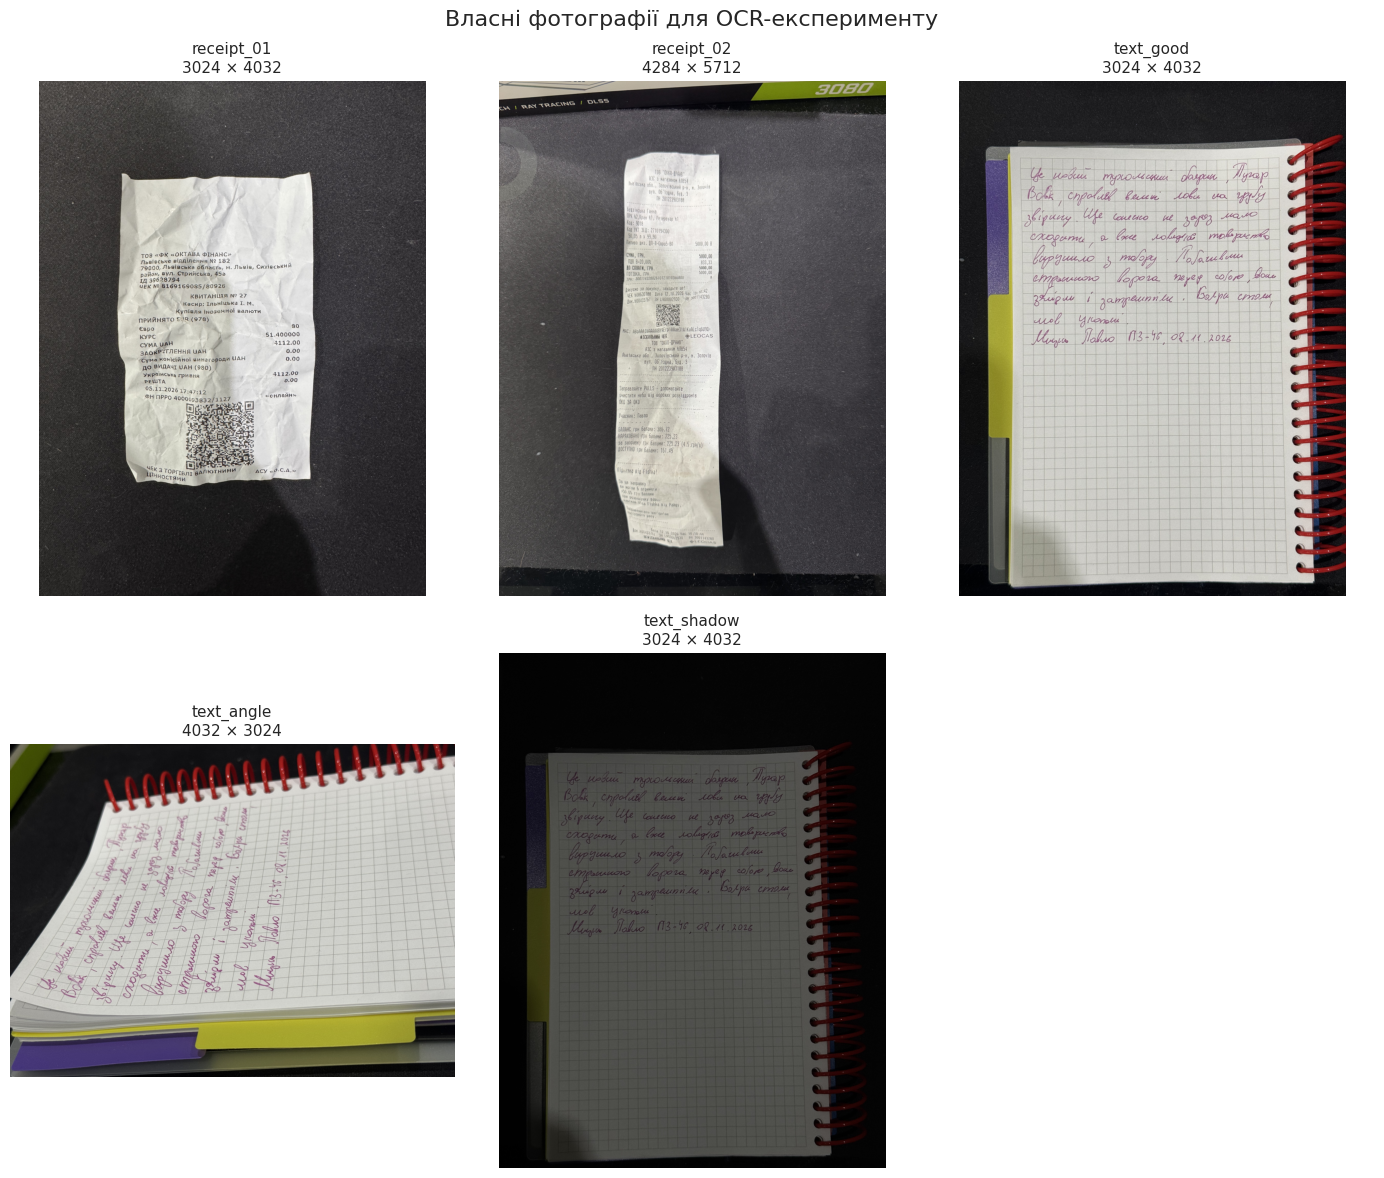

In [28]:
# Перегляд власних зображень після конвертації

fig, axes = plt.subplots(
    2,
    3,
    figsize=(14, 12)
)

for axis, row in zip(
    axes.ravel(),
    own_df.itertuples()
):
    image = Image.open(row.image_path)

    axis.imshow(image)
    axis.set_title(
        f"{row.sample_id}\n"
        f"{row.width} × {row.height}",
        fontsize=11
    )
    axis.axis("off")

# Остання клітинка залишається порожньою.
for axis in axes.ravel()[len(own_df):]:
    axis.axis("off")

plt.suptitle(
    "Власні фотографії для OCR-експерименту",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [29]:
# Створення ручних еталонних розшифровок

OWN_GROUND_TRUTH_DIR = OWN_DIR / "ground_truth"
OWN_GROUND_TRUTH_DIR.mkdir(
    parents=True,
    exist_ok=True
)

handwritten_reference = """Це новий тухольський боярин, Тугар Вовк,
справляв великі лови на грубу звірину.
Ще сонечко не зараз мало сходити,
а вже ловецьке товариство вирушило з табору.
Побачивши страшного ворога перед собою,
вони зблідли і затремтіли.
Бояри стали, мов укопані.
Мицка Павло, ПЗ-46, 08.11.2026"""

handwritten_sample_ids = [
    "text_good",
    "text_angle",
    "text_shadow"
]

for sample_id in handwritten_sample_ids:
    reference_path = (
        OWN_GROUND_TRUTH_DIR /
        f"{sample_id}.txt"
    )

    reference_path.write_text(
        handwritten_reference,
        encoding="utf-8"
    )

receipt_targets = {
    "receipt_01": {
        "date": "05.11.2026",
        "time": "17:47:12",
        "amount": "4112.00",
        "currency": "UAH"
    },
    "receipt_02": {
        "date": "12.10.2026",
        "time": "10:10:42",
        "amount": "5000.00",
        "currency": "UAH"
    }
}

receipt_targets_path = (
    OWN_GROUND_TRUTH_DIR /
    "receipt_targets.json"
)

receipt_targets_path.write_text(
    json.dumps(
        receipt_targets,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

own_handwritten_df = own_df[
    own_df["sample_id"].isin(
        handwritten_sample_ids
    )
].copy()

own_handwritten_df["ground_truth"] = (
    handwritten_reference
)

assert len(
    list(OWN_GROUND_TRUTH_DIR.glob("*.txt"))
) == 3

assert receipt_targets_path.exists()

print("Еталонний рукописний текст:")
print(handwritten_reference)

print("\nСтворено текстових файлів:", 3)
print("Цільові поля чеків:")

display(
    pd.DataFrame.from_dict(
        receipt_targets,
        orient="index"
    )
)

Еталонний рукописний текст:
Це новий тухольський боярин, Тугар Вовк,
справляв великі лови на грубу звірину.
Ще сонечко не зараз мало сходити,
а вже ловецьке товариство вирушило з табору.
Побачивши страшного ворога перед собою,
вони зблідли і затремтіли.
Бояри стали, мов укопані.
Мицка Павло, ПЗ-46, 08.11.2026

Створено текстових файлів: 3
Цільові поля чеків:


,date,time,amount,currency
receipt_01,05.11.2026,17:47:12,4112.00,UAH
receipt_02,12.10.2026,10:10:42,5000.00,UAH


## 8. Image Preprocessing

In [30]:
# Чотири конфігурації попередньої обробки зображень

PREPROCESSING_CONFIGS = [
    "original",
    "grayscale",
    "otsu",
    "adaptive"
]


def resize_for_ocr(image, max_side=2200):
    """Зменшує великі зображення без зміни пропорцій."""
    height, width = image.shape[:2]
    largest_side = max(height, width)

    if largest_side <= max_side:
        return image

    scale = max_side / largest_side

    return cv2.resize(
        image,
        None,
        fx=scale,
        fy=scale,
        interpolation=cv2.INTER_AREA
    )


def preprocess_image(image_path, config):
    """Застосовує вибрану конфігурацію обробки."""
    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        raise FileNotFoundError(
            f"Не вдалося прочитати: {image_path}"
        )

    image_bgr = resize_for_ocr(image_bgr)

    if config == "original":
        return cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB
        )

    gray = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2GRAY
    )

    if config == "grayscale":
        return gray

    if config == "otsu":
        blurred = cv2.GaussianBlur(
            gray,
            (5, 5),
            0
        )

        _, binary = cv2.threshold(
            blurred,
            0,
            255,
            cv2.THRESH_BINARY +
            cv2.THRESH_OTSU
        )

        return binary

    if config == "adaptive":
        denoised = cv2.medianBlur(
            gray,
            3
        )

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        enhanced = clahe.apply(denoised)

        return cv2.adaptiveThreshold(
            enhanced,
            255,
            cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY,
            31,
            15
        )

    raise ValueError(
        f"Невідома конфігурація: {config}"
    )


print(
    "Конфігурації обробки:",
    PREPROCESSING_CONFIGS
)

Конфігурації обробки: ['original', 'grayscale', 'otsu', 'adaptive']


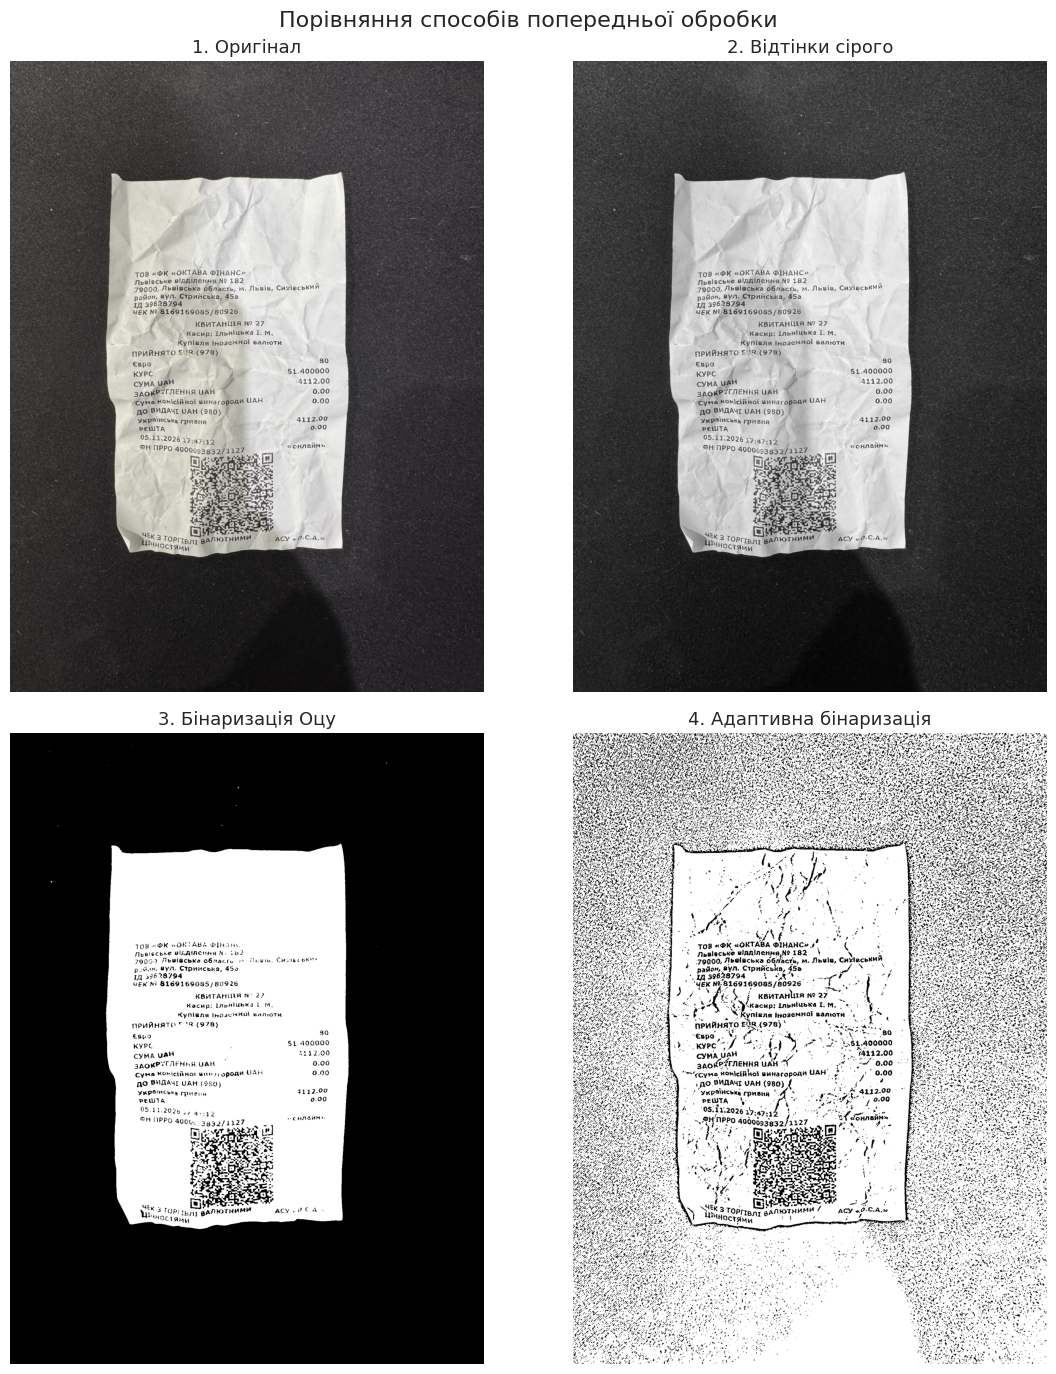

In [31]:
# Візуальне порівняння чотирьох конфігурацій

preview_image_path = own_df.loc[
    own_df["sample_id"] == "receipt_01",
    "image_path"
].iloc[0]

config_titles = {
    "original": "1. Оригінал",
    "grayscale": "2. Відтінки сірого",
    "otsu": "3. Бінаризація Оцу",
    "adaptive": "4. Адаптивна бінаризація"
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 14)
)

for axis, config in zip(
    axes.ravel(),
    PREPROCESSING_CONFIGS
):
    processed_image = preprocess_image(
        preview_image_path,
        config
    )

    if processed_image.ndim == 2:
        axis.imshow(
            processed_image,
            cmap="gray"
        )
    else:
        axis.imshow(processed_image)

    axis.set_title(
        config_titles[config],
        fontsize=13
    )
    axis.axis("off")

plt.suptitle(
    "Порівняння способів попередньої обробки",
    fontsize=16
)
plt.tight_layout()
plt.show()

## 9. Tesseract and EasyOCR

In [32]:
# Ініціалізація EasyOCR і функцій запуску двох OCR-систем

easyocr_start = time.perf_counter()

easyocr_reader = easyocr.Reader(
    ["uk", "en"],
    gpu=torch.cuda.is_available()
)

easyocr_initialization_time = (
    time.perf_counter() - easyocr_start
)


def run_tesseract_ocr(image):
    """Розпізнає український та англійський текст Tesseract."""
    start_time = time.perf_counter()

    recognized_text = pytesseract.image_to_string(
        image,
        lang="ukr+eng",
        config="--oem 3 --psm 6"
    )

    elapsed_time = (
        time.perf_counter() - start_time
    )

    return (
        normalize_text(recognized_text),
        elapsed_time
    )


def run_easyocr(image):
    """Розпізнає текст за допомогою EasyOCR."""
    start_time = time.perf_counter()

    result = easyocr_reader.readtext(
        image,
        detail=0,
        paragraph=True
    )

    recognized_text = " ".join(result)

    elapsed_time = (
        time.perf_counter() - start_time
    )

    return (
        normalize_text(recognized_text),
        elapsed_time
    )


print("EasyOCR ініціалізовано.")
print(
    "GPU:",
    torch.cuda.is_available()
)
print(
    "Час ініціалізації EasyOCR:",
    f"{easyocr_initialization_time:.2f} с"
)
print(
    "Мови Tesseract: ukr + eng"
)
print(
    "Мови EasyOCR: uk + en"
)

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.1% CompleteEasyOCR ініціалізовано.
GPU: False
Час ініціалізації EasyOCR: 10.72 с
Мови Tesseract: ukr + eng
Мови EasyOCR: uk + en


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


In [33]:
# Тестовий запуск Tesseract та EasyOCR на одному зображенні

test_sample = synthetic_df.iloc[0]

test_image = preprocess_image(
    test_sample["image_path"],
    "original"
)

tesseract_text, tesseract_time = (
    run_tesseract_ocr(test_image)
)

easyocr_text, easyocr_time = (
    run_easyocr(test_image)
)

ocr_smoke_test = pd.DataFrame([
    {
        "engine": "Tesseract",
        "CER": cer(
            test_sample["ground_truth"],
            tesseract_text
        ),
        "WER": wer(
            test_sample["ground_truth"],
            tesseract_text
        ),
        "time_seconds": tesseract_time,
        "recognized_text": tesseract_text
    },
    {
        "engine": "EasyOCR",
        "CER": cer(
            test_sample["ground_truth"],
            easyocr_text
        ),
        "WER": wer(
            test_sample["ground_truth"],
            easyocr_text
        ),
        "time_seconds": easyocr_time,
        "recognized_text": easyocr_text
    }
])

print("Еталон:")
print(test_sample["ground_truth"])

print("\nРезультати тестового запуску:")

display(
    ocr_smoke_test.round({
        "CER": 4,
        "WER": 4,
        "time_seconds": 3
    })
)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Еталон:
Це новий тухольський боярин, Тугар Вовк, справляв великі лови на грубу звірину.

Результати тестового запуску:


,engine,CER,WER,time_seconds,recognized_text
0,Tesseract,0.0000,0.0000,1.882,"Це новий тухольський боярин, Тугар Вовк, справляв великі лови на грубу звірину."
1,EasyOCR,0.0127,0.0833,7.766,"Це новий тухольський боярин, Тугар Вовк; справляв великі лови на грубу звірину."


## 10. Synthetic Data Experiment


## 11. Open Dataset Experiment

## 12. Own Images Experiment

## 13. Ablation Study

## 14. Robustness and Confidence Analysis

## 15. Error Analysis

## 16. Deskew Experiment

## 17. Date and Amount Extraction

## 18. Saving Results to JSON

## 19. Conclusions

## 20. AI Usage Declaration